# Passo 3 — Aplicação do modelo treinado aos vídeos da Liga Portugal

**Objetivo:** avaliar o modelo treinado no Passo 2 (`best.pt`) nos clips reais da FootAR e comparar com o modelo genérico do Passo 1.
O modelo foi treinado com imagens da Bundesliga (câmara tática), por isso este passo mede o impacto da **diferença de domínio** em transmissões televisivas da Liga Portugal.

## 3.1 Caminhos e carregamento do modelo


In [ ]:
from pathlib import Path
from ultralytics import YOLO
import cv2, numpy as np

BASE = Path(r"C:\Users\simao\OneDrive\Documentos\TDIA\3 ano\1_Semestre\PAIA-Projeto Aplicado de Inteligência Artificial I\OneDrive_2026-09-25\FOOTAR_DETECAO_DE_EVENTOS")
PASTA_VIDEOS = BASE / "videos"
PASTA_SAIDA  = BASE / "resultados" / "passo3"
PASTA_SAIDA.mkdir(parents=True, exist_ok=True)


candidatos = list(BASE.rglob("best*.pt")) + list((Path.home() / "Downloads").glob("best*.pt"))
print("Encontrados:", candidatos)

MODELO = candidatos[0]
print("A usar:", MODELO)
model = YOLO(str(MODELO))
print("Classes do modelo:", model.names)

videos = sorted(p for p in PASTA_VIDEOS.iterdir() if p.suffix.lower() == ".mp4")
print(f"{len(videos)} vídeos encontrados")

Encontrados: [WindowsPath('C:/Users/simao/OneDrive/Documentos/TDIA/3 ano/1_Semestre/PAIA-Projeto Aplicado de Inteligência Artificial I/OneDrive_2026-09-25/FOOTAR_DETECAO_DE_EVENTOS/dataset/football-players-detection-1/train/players_ball_v1/weights/best.pt'), WindowsPath('C:/Users/simao/Downloads/best.pt')]
A usar: C:\Users\simao\OneDrive\Documentos\TDIA\3 ano\1_Semestre\PAIA-Projeto Aplicado de Inteligência Artificial I\OneDrive_2026-09-25\FOOTAR_DETECAO_DE_EVENTOS\dataset\football-players-detection-1\train\players_ball_v1\weights\best.pt
Classes do modelo: {0: 'ball', 1: 'goalkeeper', 2: 'player', 3: 'referee'}
60 vídeos encontrados


## 3.2 Deteção num frame de cada vídeo
Para cada clip é usado o frame do meio (o mesmo critério do Passo 1), e contam-se as deteções de cada classe.

In [2]:
for video in videos:
    cap = cv2.VideoCapture(str(video))
    total = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))
    cap.set(cv2.CAP_PROP_POS_FRAMES, total // 2)
    ok, frame = cap.read()
    cap.release()
    if not ok:
        print(f"✗ {video.name}: não leu frames")
        continue

    res = model(frame, conf=0.3, imgsz=1280, verbose=False)[0]
    classes = [model.names[int(c)] for c in res.boxes.cls]
    print(f"✓ {video.name:<40} player={classes.count('player'):>2}  GR={classes.count('goalkeeper')}  "
          f"árbitro={classes.count('referee')}  bola={classes.count('ball')}")

    ok, buf = cv2.imencode(".jpg", res.plot())
    buf.tofile(str(PASTA_SAIDA / f"{video.stem}_passo3.jpg"))

✓ J1-Braga-Estrela_1-0.mp4                 player=14  GR=1  árbitro=1  bola=3
✓ J1-Braga-Estrela_1-1.mp4                 player=16  GR=1  árbitro=0  bola=3
✓ J1-Sporting-RioAve_1-0.mp4               player= 9  GR=0  árbitro=1  bola=1
✓ J1-Sporting-RioAve_2-0.mp4               player=13  GR=0  árbitro=1  bola=1
✓ J1-Sporting-RioAve_3-0.mp4               player=17  GR=0  árbitro=0  bola=0
✓ J1-Sporting-RioAve_3-1.mp4               player= 4  GR=1  árbitro=0  bola=1
✓ J10-Porto-Estoril_1-0.mp4                player=11  GR=0  árbitro=0  bola=0
✓ J10-Porto-Estoril_2-0.mp4                player=13  GR=1  árbitro=1  bola=1
✓ J10-Porto-Estoril_3-0.mp4                player=16  GR=1  árbitro=1  bola=0
✓ J10-Porto-Estoril_4-0.mp4                player=17  GR=1  árbitro=2  bola=0
✓ J10-RioAve-CasaPia_0-1.mp4               player=19  GR=0  árbitro=1  bola=1
✓ J10-RioAve-CasaPia_1-1.mp4               player=14  GR=1  árbitro=0  bola=1
✓ J10-RioAve-CasaPia_1-2.mp4               player=15  GR=0  árbi

## 3.3 Visualização
Comparação visual de um resultado: o modelo deve agora distinguir jogadores, guarda-redes, árbitro e bola.

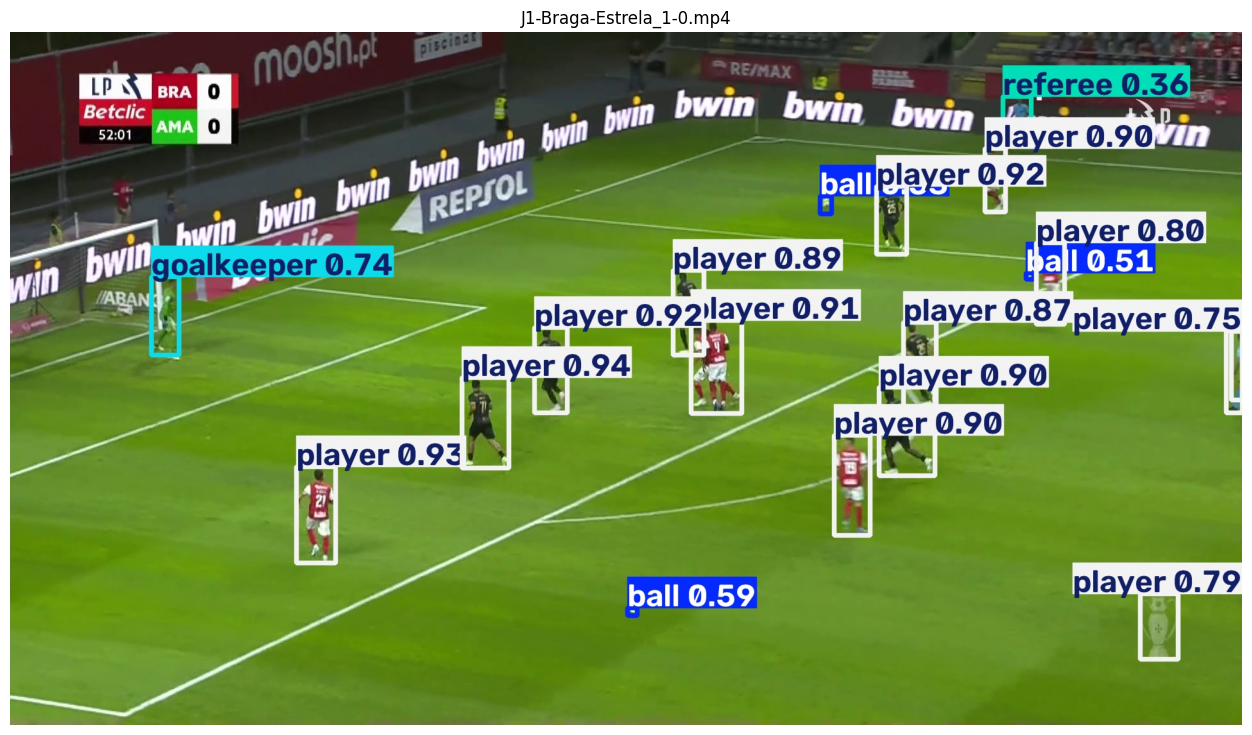

In [3]:
import matplotlib.pyplot as plt

img_path = PASTA_SAIDA / f"{videos[0].stem}_passo3.jpg"
img = cv2.imdecode(np.fromfile(str(img_path), dtype=np.uint8), cv2.IMREAD_COLOR)
plt.figure(figsize=(16, 9))
plt.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
plt.title(videos[0].name); plt.axis("off"); plt.show()

## 3.4 Pós-processamento das deteções
Os resultados mostram falsos positivos na classe `ball` (várias "bolas" no mesmo frame) e um grafismo da transmissão (troféu) detetado como `player`.
São aplicadas duas regras simples de domínio:
1. **Uma só bola por frame:** mantém-se apenas a deteção de `ball` com maior confiança, acima de um limiar mínimo.
2. **Zonas de grafismos:** ignoram-se deteções nas zonas fixas da transmissão (marcador em cima à esquerda, logótipo em baixo à direita).

Antes: 19 deteções | Depois: 16


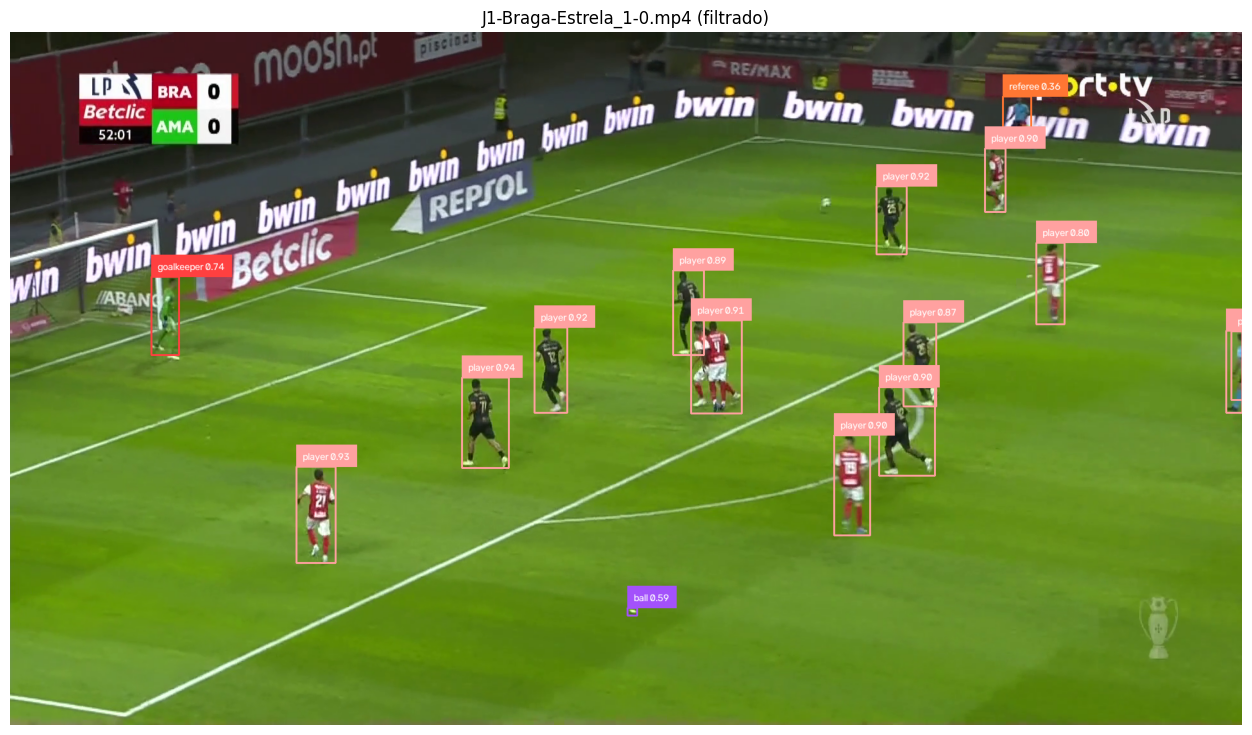

In [4]:
import supervision as sv

BOLA, GR, JOG, ARB = 0, 1, 2, 3
CONF_BOLA = 0.40          # confiança mínima para aceitar uma bola

def filtrar(res, frame):
    det = sv.Detections.from_ultralytics(res)
    h, w = frame.shape[:2]

    # 1) ignorar zonas de grafismos (marcador em cima à esquerda, logótipo em baixo à direita)
    cx = (det.xyxy[:, 0] + det.xyxy[:, 2]) / 2
    cy = (det.xyxy[:, 1] + det.xyxy[:, 3]) / 2
    em_grafismo = ((cx < 0.20 * w) & (cy < 0.20 * h)) | ((cx > 0.80 * w) & (cy > 0.75 * h))
    det = det[~em_grafismo]

    # 2) uma só bola: a de maior confiança
    bolas = det[(det.class_id == BOLA) & (det.confidence >= CONF_BOLA)]
    outros = det[det.class_id != BOLA]
    if len(bolas) > 0:
        bolas = bolas[[int(np.argmax(bolas.confidence))]]
    return sv.Detections.merge([outros, bolas])

def desenhar(frame, det):
    nomes = [f"{model.names[c]} {p:.2f}" for c, p in zip(det.class_id, det.confidence)]
    img = sv.BoxAnnotator(thickness=2).annotate(frame.copy(), det)
    return sv.LabelAnnotator(text_scale=0.5).annotate(img, det, labels=nomes)

# testar no mesmo vídeo
video = videos[0]
cap = cv2.VideoCapture(str(video))
cap.set(cv2.CAP_PROP_POS_FRAMES, int(cap.get(cv2.CAP_PROP_FRAME_COUNT)) // 2)
ok, frame = cap.read(); cap.release()

res = model(frame, conf=0.3, imgsz=1280, verbose=False)[0]
det = filtrar(res, frame)
print("Antes:", len(res.boxes), "deteções | Depois:", len(det))

plt.figure(figsize=(16, 9))
plt.imshow(cv2.cvtColor(desenhar(frame, det), cv2.COLOR_BGR2RGB))
plt.title(f"{video.name} (filtrado)"); plt.axis("off"); plt.show()

### Resultado do pós-processamento
- A regra das zonas de grafismos eliminou corretamente o troféu.
- A regra "uma só bola por frame" **escolheu a bola errada**: a deteção com maior ####confiança (0,59) é um falso positivo na relva, e a bola real (junto ao jogador nº 25) ficou por detetar.

**Conclusão:** num frame isolado, a confiança do modelo não chega para identificar a bola. É necessário usar a **informação temporal** (a bola desloca-se de forma contínua entre frames), escolhendo em cada frame a candidata mais próxima da posição anterior. Esta é a motivação para o tracking (3.5).

## 3.5 Tracking em vídeo
O modelo é aplicado a todos os frames de um clip:
- **Pessoas** (jogadores, GR, árbitro): seguidas com o algoritmo **ByteTrack**, que atribui um ID constante a cada pessoa ao longo do vídeo. É esta identidade que permite analisar os movimentos do árbitro e dos jogadores.
- **Bola**: em cada frame é escolhida, entre as candidatas, a mais próxima da última posição conhecida (continuidade temporal). O seu rasto é desenhado no vídeo.

O resultado é um vídeo anotado em `resultados/passo3`.

In [5]:
import shutil, tempfile
from collections import deque

VIDEO = videos[0]
MAX_FRAMES = 250          # ~10 s para testar (CPU é lento); None = vídeo inteiro
SALTO_MAX = 120           # píxeis máximos que a bola pode andar entre frames

cap = cv2.VideoCapture(str(VIDEO))
fps = cap.get(cv2.CAP_PROP_FPS) or 25
w, h = int(cap.get(cv2.CAP_PROP_FRAME_WIDTH)), int(cap.get(cv2.CAP_PROP_FRAME_HEIGHT))

tmp = Path(tempfile.gettempdir()) / "passo3_tracking.mp4"      # caminho sem acentos
out = cv2.VideoWriter(str(tmp), cv2.VideoWriter_fourcc(*"mp4v"), fps, (w, h))

box_ann = sv.BoxAnnotator(thickness=2)
lbl_ann = sv.LabelAnnotator(text_scale=0.5)
rasto = deque(maxlen=20)
ultima_bola = None
n = 0

while True:
    ok, frame = cap.read()
    if not ok or (MAX_FRAMES and n >= MAX_FRAMES):
        break

    # deteção + tracking (ByteTrack integrado no YOLO); persist=True mantém os IDs entre frames
    res = model.track(frame, conf=0.25, imgsz=1280, persist=True,
                      tracker="bytetrack.yaml", verbose=False)[0]
    det = sv.Detections.from_ultralytics(res)
    if det.tracker_id is None:
        det.tracker_id = np.full(len(det), -1)

    # remover grafismos
    cx = (det.xyxy[:, 0] + det.xyxy[:, 2]) / 2; cy = (det.xyxy[:, 1] + det.xyxy[:, 3]) / 2
    det = det[~(((cx < 0.20*w) & (cy < 0.20*h)) | ((cx > 0.80*w) & (cy > 0.75*h)))]

    # pessoas (jogadores, GR, árbitro) com ID
    pessoas = det[det.class_id != BOLA]

    # bola -> continuidade temporal
    bolas = det[det.class_id == BOLA]
    if len(bolas):
        centros = np.column_stack([(bolas.xyxy[:, 0] + bolas.xyxy[:, 2]) / 2,
                                   (bolas.xyxy[:, 1] + bolas.xyxy[:, 3]) / 2])
        if ultima_bola is not None:
            dist = np.linalg.norm(centros - ultima_bola, axis=1)
            i = int(np.argmin(dist))
            if dist[i] > SALTO_MAX:
                i = int(np.argmax(bolas.confidence)) if bolas.confidence.max() > 0.6 else None
        else:
            i = int(np.argmax(bolas.confidence))
        if i is not None:
            ultima_bola = centros[i]
            rasto.append(tuple(centros[i].astype(int)))

    # desenhar
    nomes = [f"#{t} {model.names[c]}" for t, c in zip(pessoas.tracker_id, pessoas.class_id)]
    img = lbl_ann.annotate(box_ann.annotate(frame.copy(), pessoas), pessoas, labels=nomes)
    for k in range(1, len(rasto)):
        cv2.line(img, rasto[k-1], rasto[k], (0, 255, 255), 2)
    if rasto:
        cv2.circle(img, rasto[-1], 8, (0, 255, 255), 2)
    out.write(img)
    n += 1
    if n % 25 == 0:
        print(f"{n} frames processados")

cap.release(); out.release()
destino = PASTA_SAIDA / f"{VIDEO.stem}_tracking.mp4"
shutil.move(str(tmp), str(destino))
print("Vídeo guardado em:", destino)

25 frames processados
50 frames processados
75 frames processados
100 frames processados
125 frames processados
150 frames processados
175 frames processados
200 frames processados
225 frames processados
250 frames processados
Vídeo guardado em: C:\Users\simao\OneDrive\Documentos\TDIA\3 ano\1_Semestre\PAIA-Projeto Aplicado de Inteligência Artificial I\OneDrive_2026-09-25\FOOTAR_DETECAO_DE_EVENTOS\resultados\passo3\J1-Braga-Estrela_1-0_tracking.mp4


### Execução do tracking
- Tracker utilizado: **ByteTrack**, integrado no Ultralytics YOLO (`model.track(..., persist=True)`), que mantém o ID de cada pessoa entre frames.
- Teste em 250 frames (~10 s) do clip `J1-Braga-Estrela_1-0.mp4`.
- Velocidade em CPU (sem GPU): ~0,4 frames/s (≈ 2,5 s por frame com `imgsz=1280`). Para processar jogos completos será necessário usar GPU (Colab) ou reduzir a resolução.

In [6]:
%pip install imageio-ffmpeg
import imageio_ffmpeg, subprocess


ffmpeg = imageio_ffmpeg.get_ffmpeg_exe()
entrada = PASTA_SAIDA / f"{VIDEO.stem}_tracking.mp4"
tmp_in  = Path(tempfile.gettempdir()) / "in.mp4"
tmp_out = Path(tempfile.gettempdir()) / "out.mp4"
shutil.copy(entrada, tmp_in)

subprocess.run([ffmpeg, "-y", "-i", str(tmp_in), "-c:v", "libx264", "-pix_fmt", "yuv420p", str(tmp_out)], check=True)
final = PASTA_SAIDA / f"{VIDEO.stem}_tracking_h264.mp4"
shutil.move(str(tmp_out), str(final))
print("Vídeo convertido:", final)


[notice] A new release of pip is available: 26.1.1 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


Note: you may need to restart the kernel to use updated packages.
Vídeo convertido: C:\Users\simao\OneDrive\Documentos\TDIA\3 ano\1_Semestre\PAIA-Projeto Aplicado de Inteligência Artificial I\OneDrive_2026-09-25\FOOTAR_DETECAO_DE_EVENTOS\resultados\passo3\J1-Braga-Estrela_1-0_tracking_h264.mp4


### Análise do vídeo com tracking
- **Identidade dos jogadores (IDs):** [mantêm-se / mudam quando os jogadores se cruzam ou saem do enquadramento]
- **Bola:** [o rasto segue a bola real / perde-se em passes rápidos / salta para falsos positivos]
- **Árbitro:** [detetado na maior parte dos frames / detetado só quando está próximo da câmara]
- **Velocidade:** ~0,4 frames/s em CPU. O processamento de clips completos terá de ser feito em GPU.

(VIDEO EM RESULTADOS/PASSO3)


### Análise do vídeo com tracking (frame aos 5 s)
- **Deteção de pessoas:** a maioria dos jogadores é detetada, incluindo jogadores próximos uns dos outros; o guarda-redes é bem identificado e o grafismo do troféu deixou de ser detetado.
- **Árbitros:** o árbitro assistente é identificado como `referee` (confiança baixa, por estar longe). A classificação do árbitro principal tem de ser confirmada ao longo do vídeo.
- **Identidade (IDs):** aos 5 s já existem IDs acima de 600, o que indica **trocas e perdas frequentes de identidade**. O tracker cria IDs novos quando um jogador é ocluído, sai do enquadramento ou a deteção falha num frame.
- **Bola:** o rasto segue um falso positivo; a bola real (junto ao jogador #400) não é selecionada. A deteção da bola continua a ser o ponto mais fraco.
- **Equipas:** o modelo não distingue Braga (vermelho) de Estrela (preto), o que é indispensável para foras de jogo e faltas.

**Próximos passos:** (1) classificar as equipas pela cor do equipamento; (2) melhorar a bola com um modelo dedicado e/ou deteção por zonas (*slicing*); (3) estabilizar os IDs com parâmetros de tracking mais tolerantes.

# Passo 4 — Classificação das equipas pela cor do equipamento

O modelo de deteção não distingue as equipas (todos os jogadores são `player`). Para foras de jogo e faltas é necessário saber a que equipa pertence cada jogador.

**Método (não supervisionado):**
1. Recortar a zona da camisola de cada `player` (parte superior da caixa).
2. Remover os píxeis verdes (relva) no espaço de cor HSV.
3. Representar cada jogador por um histograma de cor (H × S).
4. Agrupar os jogadores em 2 equipas com **K-Means (k = 2)**.

Guarda-redes e árbitros são excluídos, porque usam cores diferentes das equipas.

## 4.1b Validação do número de grupos (método do cotovelo e silhueta)
Embora o número de equipas seja conhecido (k = 2), valida-se empiricamente essa escolha:
- **Método do cotovelo:** inércia (soma das distâncias ao centróide) para k = 1…6. O "cotovelo" é o ponto a partir do qual aumentar k quase não reduz a inércia.
- **Coeficiente de silhueta:** mede a separação entre grupos (−1 a 1); o k com maior silhueta é o que melhor separa os dados.

143 jogadores recolhidos em 9 frames de J1-Braga-Estrela_1-0.mp4


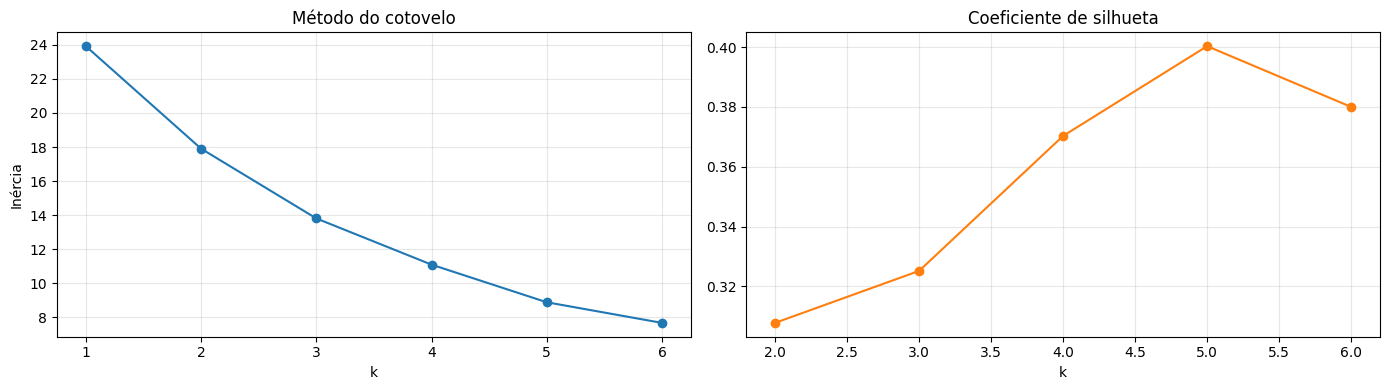

k=1: —
k=2: silhueta=0.308
k=3: silhueta=0.325
k=4: silhueta=0.370
k=5: silhueta=0.400
k=6: silhueta=0.380


In [9]:

import sys, subprocess
try:
    from sklearn.cluster import KMeans
    from sklearn.metrics import silhouette_score
except ImportError:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "scikit-learn"])
    from sklearn.cluster import KMeans
    from sklearn.metrics import silhouette_score

from pathlib import Path
from ultralytics import YOLO
import cv2, numpy as np, matplotlib.pyplot as plt

BASE = Path(r"C:\Users\simao\OneDrive\Documentos\TDIA\3 ano\1_Semestre\PAIA-Projeto Aplicado de Inteligência Artificial I\OneDrive_2026-09-25\FOOTAR_DETECAO_DE_EVENTOS")
model = YOLO(str(list(BASE.rglob("best*.pt"))[0]))
videos = sorted((BASE / "videos").glob("*.mp4"))
JOG = 2

def cor_camisola(frame, caixa):
    x1, y1, x2, y2 = caixa.astype(int)
    h = y2 - y1
    crop = frame[max(0, y1 + int(0.15*h)): y1 + int(0.50*h), max(0, x1):x2]
    if crop.size == 0:
        return None
    hsv = cv2.cvtColor(crop, cv2.COLOR_BGR2HSV)
    mascara = cv2.bitwise_not(cv2.inRange(hsv, (35, 40, 40), (85, 255, 255)))   # tira a relva
    hist = cv2.calcHist([hsv], [0, 1], mascara, [8, 4], [0, 180, 0, 256]).flatten()
    return hist / (hist.sum() + 1e-6)

# recolher jogadores de 10 frames do primeiro vídeo
video = videos[0]
cap = cv2.VideoCapture(str(video))
total = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))
amostras, frames_guardados = [], []
for idx in np.linspace(0, total - 1, 10).astype(int):
    cap.set(cv2.CAP_PROP_POS_FRAMES, int(idx)); ok, frame = cap.read()
    if not ok:
        continue
    r = model(frame, conf=0.3, imgsz=1280, verbose=False)[0]
    for caixa, c in zip(r.boxes.xyxy.cpu().numpy(), r.boxes.cls.cpu().numpy()):
        if int(c) == JOG:
            f = cor_camisola(frame, caixa)
            if f is not None:
                amostras.append(f)
    frames_guardados.append(frame)
cap.release()
X = np.array(amostras)
print(f"{len(X)} jogadores recolhidos em {len(frames_guardados)} frames de {video.name}")

# método do cotovelo + silhueta
ks = range(1, 7)
inercias, silhuetas = [], []
for k in ks:
    km = KMeans(n_clusters=k, n_init=10, random_state=0).fit(X)
    inercias.append(km.inertia_)
    silhuetas.append(silhouette_score(X, km.labels_) if k > 1 else np.nan)

fig, (a1, a2) = plt.subplots(1, 2, figsize=(14, 4))
a1.plot(ks, inercias, "o-"); a1.set_title("Método do cotovelo"); a1.set_xlabel("k"); a1.set_ylabel("Inércia")
a2.plot(ks, silhuetas, "o-", color="tab:orange"); a2.set_title("Coeficiente de silhueta"); a2.set_xlabel("k")
for a in (a1, a2): a.grid(alpha=0.3)
plt.tight_layout(); plt.show()

for k, s in zip(ks, silhuetas):
    print(f"k={k}: silhueta={s:.3f}" if k > 1 else "k=1: —")

### Resultado da validação de k (histograma H×S)
- O método do cotovelo não apresenta um cotovelo claro e o coeficiente de silhueta é **máximo em k = 5 (0,40)** e mínimo em k = 2 (0,31).
- Conclusão: com esta representação da cor, os jogadores **não formam dois grupos bem separados**. O problema não está no número de equipas (que é 2), mas nas *features*:
  - o histograma usa apenas Tom (H) e Saturação (S) e ignora o Brilho (V); num equipamento preto (Estrela), o tom é praticamente aleatório;
  - o recorte inclui pele, números, calções e fundo (publicidade).
- **Melhoria:** representar cada jogador pela **cor mediana da camisola no espaço CIELAB** (L = luminosidade, a/b = cor), que separa melhor preto de vermelho e é mais robusta a variações de iluminação.

128 jogadores


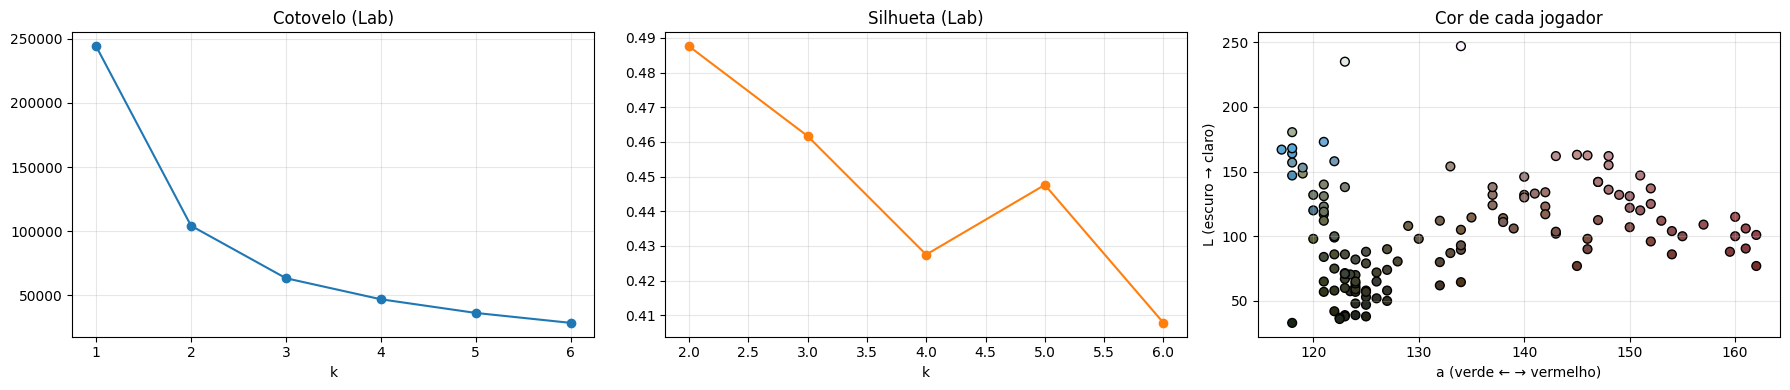

k=1: —
k=2: silhueta=0.488
k=3: silhueta=0.462
k=4: silhueta=0.427
k=5: silhueta=0.448
k=6: silhueta=0.408


In [10]:
def cor_lab(frame, caixa):
    x1, y1, x2, y2 = caixa.astype(int)
    h, w = y2 - y1, x2 - x1
    # zona central do tronco (evita braços, calções e fundo)
    crop = frame[max(0, y1 + int(0.20*h)): y1 + int(0.45*h), max(0, x1 + int(0.25*w)): x2 - int(0.25*w)]
    if crop.size == 0:
        return None
    hsv = cv2.cvtColor(crop, cv2.COLOR_BGR2HSV)
    nao_relva = cv2.inRange(hsv, (35, 40, 40), (85, 255, 255)) == 0
    lab = cv2.cvtColor(crop, cv2.COLOR_BGR2LAB)[nao_relva]
    if len(lab) < 10:
        return None
    return np.median(lab, axis=0)          # [L, a, b]

# recalcular as features com os mesmos frames
amostras = []
for frame in frames_guardados:
    r = model(frame, conf=0.3, imgsz=1280, verbose=False)[0]
    for caixa, c in zip(r.boxes.xyxy.cpu().numpy(), r.boxes.cls.cpu().numpy()):
        if int(c) == JOG:
            f = cor_lab(frame, caixa)
            if f is not None:
                amostras.append(f)
X_lab = np.array(amostras)
print(f"{len(X_lab)} jogadores")

# cotovelo + silhueta com a nova representação
inercias, silhuetas = [], []
for k in ks:
    km = KMeans(n_clusters=k, n_init=10, random_state=0).fit(X_lab)
    inercias.append(km.inertia_)
    silhuetas.append(silhouette_score(X_lab, km.labels_) if k > 1 else np.nan)

fig, (a1, a2, a3) = plt.subplots(1, 3, figsize=(18, 4))
a1.plot(ks, inercias, "o-"); a1.set_title("Cotovelo (Lab)"); a1.set_xlabel("k")
a2.plot(ks, silhuetas, "o-", color="tab:orange"); a2.set_title("Silhueta (Lab)"); a2.set_xlabel("k")
# visualização: cada ponto é um jogador, pintado com a sua própria cor
cores_rgb = cv2.cvtColor(X_lab.astype(np.uint8).reshape(-1, 1, 3), cv2.COLOR_LAB2RGB).reshape(-1, 3) / 255
a3.scatter(X_lab[:, 1], X_lab[:, 0], c=cores_rgb, edgecolors="k", s=40)
a3.set_xlabel("a (verde ← → vermelho)"); a3.set_ylabel("L (escuro → claro)"); a3.set_title("Cor de cada jogador")
for a in (a1, a2, a3): a.grid(alpha=0.3)
plt.tight_layout(); plt.show()

for k, s in zip(ks, silhuetas):
    print(f"k={k}: silhueta={s:.3f}" if k > 1 else "k=1: —")

### Resultado da validação de k (cor mediana em CIELAB)
| k | 2 | 3 | 4 | 5 | 6 |
|---|---|---|---|---|---|
| Silhueta | **0,488** | 0,462 | 0,427 | 0,448 | 0,408 |

- O **método do cotovelo** apresenta uma quebra clara em **k = 2** e o **coeficiente de silhueta é máximo em k = 2** (0,488, contra 0,308 com o histograma H×S).
- A representação pela cor mediana em CIELAB separa bem as duas equipas: equipamentos escuros (Estrela da Amadora) com valores baixos de L e de a, e equipamentos vermelhos (SC Braga) com valores altos de a.
- **Casos atípicos:** pontos azulados correspondem provavelmente a **árbitros detetados como `player`**, e pontos muito claros a recortes com mangas/calções brancos ou reflexos. Estes casos são tratados como "indefinidos" quando estão longe de ambos os centróides.

**Conclusão:** k = 2 fica validado empiricamente, e a mudança de representação (H×S → CIELAB) foi decisiva para separar as equipas.

## 4.2 Classificação das equipas (K-Means, k = 2)
Treina-se o K-Means com k = 2 nas cores CIELAB. Cada jogador é atribuído à equipa do centróide mais próximo; se estiver demasiado longe de ambos (distância acima do percentil 95), fica **indefinido** (possível árbitro mal classificado ou recorte ruidoso).

Jogadores por equipa: [66 62]
Cor média de cada equipa (BGR): [[117, 120, 144], [49, 63, 70]]


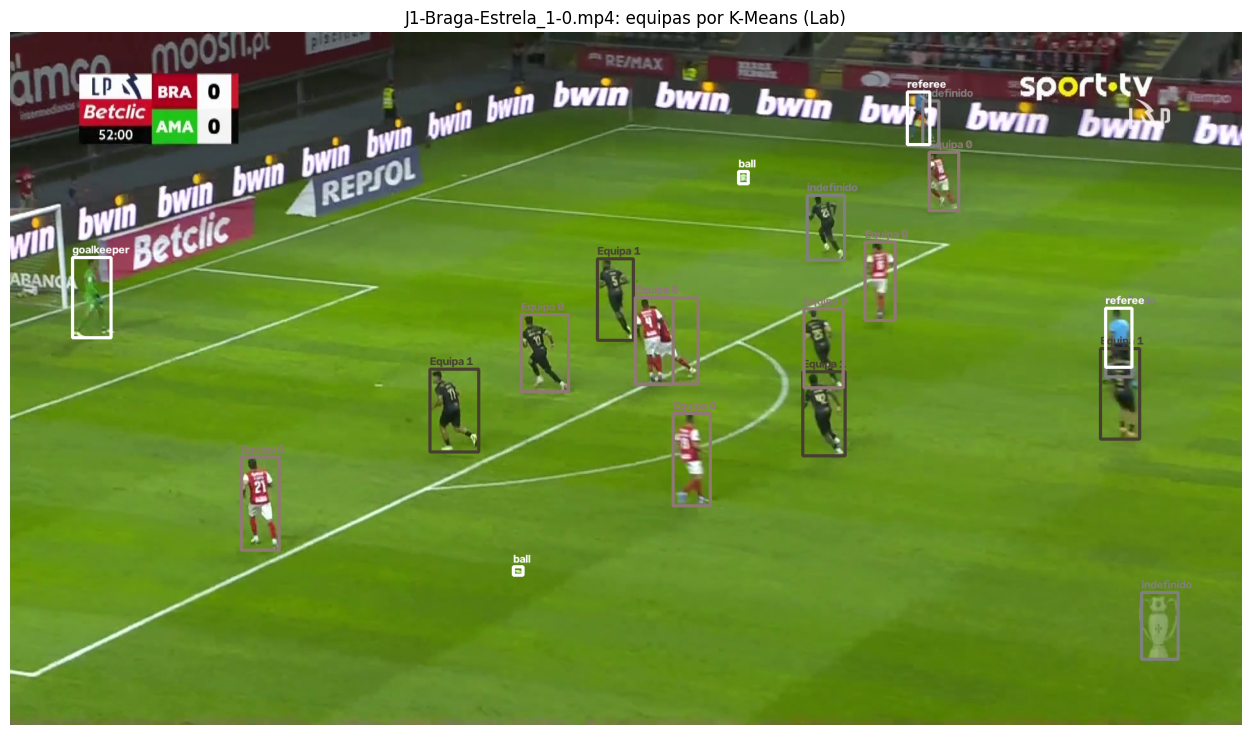

In [11]:
kmeans = KMeans(n_clusters=2, n_init=10, random_state=0).fit(X_lab)
dist_treino = np.min(kmeans.transform(X_lab), axis=1)
LIMIAR = np.percentile(dist_treino, 95)

# dar nome às equipas pela cor dos centróides (o mais "vermelho" = maior a)
centro_rgb = cv2.cvtColor(kmeans.cluster_centers_.astype(np.uint8).reshape(-1, 1, 3), cv2.COLOR_LAB2BGR).reshape(-1, 3)
print("Jogadores por equipa:", np.bincount(kmeans.labels_))
print("Cor média de cada equipa (BGR):", centro_rgb.tolist())

def equipa(frame, caixa):
    f = cor_lab(frame, caixa)
    if f is None:
        return -1
    d = kmeans.transform([f])[0]
    return -1 if d.min() > LIMIAR else int(np.argmin(d))

# visualizar num frame
frame = frames_guardados[len(frames_guardados) // 2]
r = model(frame, conf=0.3, imgsz=1280, verbose=False)[0]
img = frame.copy()
for caixa, c in zip(r.boxes.xyxy.cpu().numpy(), r.boxes.cls.cpu().numpy()):
    x1, y1, x2, y2 = caixa.astype(int)
    if int(c) == JOG:
        e = equipa(frame, caixa)
        cor = tuple(int(v) for v in centro_rgb[e]) if e >= 0 else (128, 128, 128)
        txt = f"Equipa {e}" if e >= 0 else "indefinido"
    else:
        cor, txt = (255, 255, 255), model.names[int(c)]
    cv2.rectangle(img, (x1, y1), (x2, y2), cor, 3)
    cv2.putText(img, txt, (x1, y1 - 6), cv2.FONT_HERSHEY_SIMPLEX, 0.6, cor, 2)

plt.figure(figsize=(16, 9)); plt.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
plt.title(f"{video.name}: equipas por K-Means (Lab)"); plt.axis("off"); plt.show()

### Resultado da classificação num frame
- A maioria dos jogadores é corretamente atribuída: **Equipa 0 = SC Braga** (vermelho), **Equipa 1 = Estrela da Amadora** (preto).
- Árbitro principal e árbitro assistente são detetados como `referee` e excluídos da classificação de equipas; o guarda-redes também é tratado à parte.
- Erros: 1 jogador do Estrela atribuído ao Braga e 1 jogador "indefinido" (recortes com pouca camisola visível: jogador de lado, de costas ou distante).
- **Melhoria:** combinar com o tracking. Como cada jogador tem um ID, a equipa é decidida por **votação maioritária ao longo dos frames**, o que corrige erros pontuais.

## 4.3 Vídeo com tracking + equipas (votação temporal)
Para cada ID do tracker guarda-se a equipa estimada em cada frame; a equipa mostrada é a **mais votada** até esse momento.
Aplicam-se também o filtro de grafismos e a seleção temporal da bola (Passo 3).

In [14]:
import shutil, tempfile, subprocess
from collections import deque, defaultdict, Counter
try:
    import imageio_ffmpeg
except ImportError:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "imageio-ffmpeg"]); import imageio_ffmpeg

BOLA, GR, JOG, ARB = 0, 1, 2, 3
PASTA_SAIDA = BASE / "resultados" / "passo4"; PASTA_SAIDA.mkdir(parents=True, exist_ok=True)
MAX_FRAMES = 250
SALTO_MAX = 120

cap = cv2.VideoCapture(str(video))
fps = cap.get(cv2.CAP_PROP_FPS) or 25
W, H = int(cap.get(cv2.CAP_PROP_FRAME_WIDTH)), int(cap.get(cv2.CAP_PROP_FRAME_HEIGHT))
tmp = Path(tempfile.gettempdir()) / "passo4_raw.mp4"
out = cv2.VideoWriter(str(tmp), cv2.VideoWriter_fourcc(*"mp4v"), fps, (W, H))

votos = defaultdict(Counter)          # id -> contagem de equipas
rasto, ultima_bola, n = deque(maxlen=20), None, 0
model.predictor = None                 # reinicia o tracker

while True:
    ok, frame = cap.read()
    if not ok or (MAX_FRAMES and n >= MAX_FRAMES):
        break
    r = model.track(frame, conf=0.25, imgsz=1280, persist=True, tracker=str(TRACKER), verbose=False)[0]
    caixas = r.boxes.xyxy.cpu().numpy(); cls = r.boxes.cls.cpu().numpy().astype(int)
    conf = r.boxes.conf.cpu().numpy()
    ids = r.boxes.id.cpu().numpy().astype(int) if r.boxes.id is not None else np.full(len(cls), -1)

    img = frame.copy()
    bolas = []
    for caixa, c, p, tid in zip(caixas, cls, conf, ids):
        x1, y1, x2, y2 = caixa.astype(int)
        cx, cy = (x1 + x2) / 2, (y1 + y2) / 2
        if (cx < 0.20*W and cy < 0.20*H) or (cx > 0.80*W and cy > 0.75*H):   # grafismos
            continue
        if c == BOLA:
            bolas.append((np.array([cx, cy]), p)); continue
        if c == JOG:
            e = equipa(frame, caixa)
            if e >= 0 and tid >= 0:
                votos[tid][e] += 1
            e_final = votos[tid].most_common(1)[0][0] if votos[tid] else -1
            cor = tuple(int(v) for v in centro_rgb[e_final]) if e_final >= 0 else (128, 128, 128)
            txt = f"#{tid} Eq.{e_final}" if e_final >= 0 else f"#{tid} ?"
        elif c == ARB:
            cor, txt = (0, 255, 255), f"#{tid} ARBITRO"
        else:
            cor, txt = (255, 255, 255), f"#{tid} GR"
        cv2.rectangle(img, (x1, y1), (x2, y2), cor, 2)
        cv2.putText(img, txt, (x1, y1 - 6), cv2.FONT_HERSHEY_SIMPLEX, 0.55, cor, 2)

    # bola: candidata mais próxima da anterior
    if bolas:
        centros = np.array([b[0] for b in bolas]); confs = np.array([b[1] for b in bolas])
        if ultima_bola is not None:
            d = np.linalg.norm(centros - ultima_bola, axis=1); i = int(np.argmin(d))
            if d[i] > SALTO_MAX:
                i = int(np.argmax(confs)) if confs.max() > 0.6 else None
        else:
            i = int(np.argmax(confs))
        if i is not None:
            ultima_bola = centros[i]; rasto.append(tuple(centros[i].astype(int)))
    for k in range(1, len(rasto)):
        cv2.line(img, rasto[k-1], rasto[k], (0, 255, 255), 2)
    if rasto:
        cv2.circle(img, rasto[-1], 8, (0, 255, 255), 2)

    out.write(img); n += 1
    if n % 25 == 0:
        print(f"{n} frames")

cap.release(); out.release()
final_tmp = Path(tempfile.gettempdir()) / "passo4_h264.mp4"
subprocess.run([imageio_ffmpeg.get_ffmpeg_exe(), "-y", "-i", str(tmp), "-c:v", "libx264",
                "-pix_fmt", "yuv420p", str(final_tmp)], check=True, capture_output=True)
destino = PASTA_SAIDA / f"{video.stem}_equipas.mp4"
shutil.move(str(final_tmp), str(destino))
print("Vídeo guardado em:", destino)

25 frames
50 frames
75 frames
100 frames
125 frames
150 frames
175 frames
200 frames
225 frames
250 frames
Vídeo guardado em: C:\Users\simao\OneDrive\Documentos\TDIA\3 ano\1_Semestre\PAIA-Projeto Aplicado de Inteligência Artificial I\OneDrive_2026-09-25\FOOTAR_DETECAO_DE_EVENTOS\resultados\passo4\J1-Braga-Estrela_1-0_equipas.mp4


### Resultado do vídeo com equipas
- As equipas ficam corretamente identificadas e estáveis na maior parte do vídeo (Braga / Estrela), e os árbitros são destacados.
- **Limitação:** em movimentos rápidos da câmara, os jogadores ficam desfocados (*motion blur*), a confiança da deteção baixa e o jogador deixa de ser detetado durante alguns frames. Ao reaparecer recebe um ID novo, e a votação da equipa recomeça.
- **Melhoria:** usar o tracker **BoT-SORT com compensação do movimento da câmara (GMC)**, aumentar a memória do tracker (`track_buffer`) e baixar os limiares de confiança do tracking.

In [15]:
import ultralytics, yaml

origem = Path(ultralytics.__file__).parent / "cfg" / "trackers" / "botsort.yaml"
cfg = yaml.safe_load(open(origem))
cfg.update(
    track_buffer=60,          # "lembra-se" de um jogador desaparecido durante ~2,4 s (60 frames)
    track_high_thresh=0.3,    # aceita deteções com menos confiança (jogadores desfocados)
    track_low_thresh=0.1,
    new_track_thresh=0.3,     # cria IDs novos com menos exigência
    gmc_method="sparseOptFlow"  # compensação do movimento da câmara
)
TRACKER = BASE / "tracker_footar.yaml"
yaml.safe_dump(cfg, open(TRACKER, "w"))
print(cfg)

{'tracker_type': 'botsort', 'track_high_thresh': 0.3, 'track_low_thresh': 0.1, 'new_track_thresh': 0.3, 'track_buffer': 60, 'match_thresh': 0.8, 'fuse_score': True, 'gmc_method': 'sparseOptFlow', 'proximity_thresh': 0.5, 'appearance_thresh': 0.8, 'with_reid': False, 'model': 'auto'}
